# Setup and data loading

In [5]:
import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# Specify the columns we need to save for the analysis
cols = ["Vessel Name", "Departure Date", "Departure Country", "Commodity","EU voyage type",
"Distance (nm)", "Avg Speed (kn)", "VLSFO Cons (t)", "HSFO Cons (t)", "MGO Cons (t)", "CO2 Total (t)", 
"Leg Type", "Vessel Dwt"]

# Load the dataset
clean_dataset = pd.read_csv("../Data/combin-all.csv", usecols=cols)

# Convert dates to proper datetime objects
clean_dataset["Departure Date"] = pd.to_datetime(clean_dataset["Departure Date"])

# Variable construction

In [6]:
# Creation of the treatment variable 
# We map the voyage type (intra EU, from EU or international) to the actual percentage of emissions
# that the ship must pay for under EU law (100% for intra EU, 50% for international)
ets_mapping = {'Intra_EU': 1.0, 'To_EU': 0.5, 'From_EU': 0.5, '0': 0.0, 0: 0.0}
clean_dataset["ETS_Rate"] = clean_dataset["EU voyage type"].map(ets_mapping).fillna(0.0)

# We create a binary indicator for the policy implementation date
# 0 = Baseline period (Voyages in 2022 and 2023 when carbon tax was not yet implemented)
# 1 = Treatment period (Voyages in 2024 when carbon tax was introduced)
clean_dataset["Post2024"] = (clean_dataset["Departure Date"] >= "2024-01-01").astype(int)

# We create the interaction term for the DiD regressions, which is simply the
# product of treatment intensity (ETS_Rate) and time (Post2024)
# Interpretation : it answers: "How much did the behavior of EU exposed ships deviate from 
# their usual patterns, compared to how much the non EU ships changed 
# at the exact same time?"
clean_dataset["Interaction"] = clean_dataset["ETS_Rate"] * clean_dataset["Post2024"]

print(clean_dataset[["EU voyage type", "ETS_Rate", "Post2024", "Interaction"]].head())

# Creation/transformation of the outcome variables
# We use the log of CO2 divided by distance to get a more normalized distribution
# and to interpret results in % terms (e.g., -0.05 = -5%)
clean_dataset["log_CO2_per_nm"] = np.log(clean_dataset["CO2 Total (t)"] / clean_dataset["Distance (nm)"])

# To see if ships switched to cleaner fuel, we look at the percentage of each 
# fuel type burned relative to the total voyage fuel.
clean_dataset["Total_Fuel"] = clean_dataset[["VLSFO Cons (t)", "HSFO Cons (t)", "MGO Cons (t)"]].sum(axis=1)

# Divide each type by total. fillna(0) handles cases where Total_Fuel is 0 (preventing errors).
clean_dataset["MGO_Share"]   = (clean_dataset["MGO Cons (t)"].fillna(0) / clean_dataset["Total_Fuel"]).fillna(0)
clean_dataset["HSFO_Share"]  = (clean_dataset["HSFO Cons (t)"].fillna(0) / clean_dataset["Total_Fuel"]).fillna(0)
clean_dataset["VLSFO_Share"] = (clean_dataset["VLSFO Cons (t)"].fillna(0) / clean_dataset["Total_Fuel"]).fillna(0)

print(clean_dataset[["log_CO2_per_nm", "MGO_Share", "HSFO_Share", "VLSFO_Share"]].head())

print("Rows before cleaning:", len(clean_dataset))

# Replace missing values by zero for regressions
# But this line acts as a safety net, actually we don't have missing values in the variables specified below
clean_dataset = clean_dataset.replace([np.inf, -np.inf], np.nan).dropna(
    subset=["log_CO2_per_nm", "Avg Speed (kn)", "Departure Country"])

print("Rows after cleaning: ", len(clean_dataset))

# Creation of a time index for the TWFE, e.g we turn 2024-01-15 into 2024-01.
# This monthly aggregation smooths out daily operational noise (like weather or port delays),
# to isolate the behavior shifts caused by the EU ETS implementation
clean_dataset["YearMonth"] = clean_dataset["Departure Date"].dt.to_period("M").astype(str)

# We rank the months (e.g., Jan 2022 = 0, Feb 2022 = 1, etc.)
# This variable is then use to create time fixed effects and to control for
# linear pre-existing trends in the regressions
month_rank = {v: i for i, v in enumerate(sorted(clean_dataset["YearMonth"].unique()))}
clean_dataset["TimeIdx"] = clean_dataset["YearMonth"].map(month_rank)

print("Preview of Time Indexing:")
print(clean_dataset[["Departure Date", "YearMonth", "TimeIdx"]].head())
print("Unique Months found:", sorted(clean_dataset["YearMonth"].unique()))

# Checks about the NA and 0 values
fuel_cols = ["MGO Cons (t)", "HSFO Cons (t)", "VLSFO Cons (t)"]

na_counts = clean_dataset[fuel_cols].isna().sum() # count NA
zero_counts = (clean_dataset[fuel_cols] == 0).sum() # count zero values
na_pct = (clean_dataset[fuel_cols].isna().mean() * 100).round(2) # percentage of NA

verification_df = pd.DataFrame({
    "Missing (NA)": na_counts,
    "Actual Zeros (0.0)": zero_counts,
    "% Missing": na_pct})

print("Verification of Fuel Consumption Data (Before Imputation):", verification_df)

  EU voyage type  ETS_Rate  Post2024  Interaction
0              0       0.0         0          0.0
1              0       0.0         0          0.0
2              0       0.0         0          0.0
3              0       0.0         0          0.0
4              0       0.0         0          0.0
   log_CO2_per_nm  MGO_Share  HSFO_Share  VLSFO_Share
0       -1.297731   0.008281         0.0     0.991719
1       -1.308187   0.007705         0.0     0.992295
2       -1.304024   0.007976         0.0     0.992024
3       -1.301240   0.008121         0.0     0.991879
4       -1.299746   0.008192         0.0     0.991808
Rows before cleaning: 3819170
Rows after cleaning:  3819170
Preview of Time Indexing:
       Departure Date YearMonth  TimeIdx
0 2022-03-03 22:30:04   2022-03      110
1 2022-07-17 03:30:13   2022-07      114
2 2022-08-01 03:25:39   2022-08      115
3 2022-10-22 07:04:23   2022-10      117
4 2022-01-19 11:36:18   2022-01      108
Unique Months found: ['2013-01', '2013-02', 

# Hierarchical clustering

In [7]:
# We use only 2023 data to build our clusters. If we used 2024 data, the clusters would be biased
# by ships already reacting to the policy
clean_dataset_2023 = clean_dataset[clean_dataset["Departure Date"].dt.year == 2023].copy()
print("2023 Observations:", len(clean_dataset_2023))

# HSFO Cons (t) has around 96% NA in the raw data, so we deliberately exclude it from the fuel share
# computation. Using it would propagate near universal missingness into our clustering features.
# We proxy the fuel mix with MGO share over the two reliable fuels only. That is an issue for the regressions
# that would need to be adress when we will interpret the results
clean_dataset_2023["Total_Fuel"] = clean_dataset_2023["MGO Cons (t)"].fillna(0) + \
                                    clean_dataset_2023["VLSFO Cons (t)"].fillna(0)

clean_dataset_2023["MGO_Share_proxy"] = np.where(
    clean_dataset_2023["Total_Fuel"] > 0,
    clean_dataset_2023["MGO Cons (t)"].fillna(0) / clean_dataset_2023["Total_Fuel"],
    np.nan)

# A country with a high laden ratio is primarily an origin/export hub; low ratio = destination/import hub.
# This captures a structural trade dimension that EU exposure alone cannot
clean_dataset_2023["Is_Laden"] = (clean_dataset_2023["Leg Type"] == "Laden").astype(int)

# We now summarize each departure country on 6 independent dimensions:
# Distance : Long-haul vs short-sea trade profile
# CO2 intensity : Structural carbon footprint of the shipping activity
# EU exposure : How much of their trade is already within the EU ETS scope
# Speed : Operational tempo — fast commercial routes vs slow commodity hauls
# Vessel size : Large DWT = bulk commodities; small DWT = general/project cargo
# Fuel mix : MGO-leaning (cleaner, scrubber-free) vs VLSFO-leaning fleets
country_profiles = clean_dataset_2023.groupby("Departure Country").agg(
    Avg_Distance  = ("Distance (nm)", "mean"),
    Avg_CO2_Intensity  = ("log_CO2_per_nm", "mean"),
    EU_Exposure_Ratio  = ("ETS_Rate", "mean"),
    Avg_Speed = ("Avg Speed (kn)", "mean"),
    Avg_DWT = ("Vessel Dwt", "mean"),
    Avg_MGO_Share  = ("MGO_Share_proxy", "mean"),
    Laden_Ratio = ("Is_Laden", "mean"),
    Total_Voyages = ("Vessel Name", "count")).dropna()

# We remove countries with fewer than 50 voyages. This ensures our cluster averages
# aren't ruined by a single weird voyage
country_profiles = country_profiles[country_profiles["Total_Voyages"] > 50]
print("Number of countries to be clustered:", len(country_profiles))
print(country_profiles.head())

# All 6 features are on different scales (nm, knots, tonnes, 0-1 ratios)
# Clustering algorithms are sensitive to big numbers, so we standardize to mean=0, variance=1
features = ["Avg_Distance", "Avg_CO2_Intensity", "EU_Exposure_Ratio", "Avg_Speed", "Avg_DWT", "Avg_MGO_Share", "Laden_Ratio"]

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(country_profiles[features])

# With 7 features, Ward's linkage can become noisy in high-dimensional space. PCA extracts
# the principal axes of variation and reduces noise from correlated features(e.g., Distance and
# Speed are likely correlated). We keep enough components to explain 80% of the variance
pca = PCA(n_components=0.80, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"PCA retained {pca.n_components_} components explaining "
      f"{pca.explained_variance_ratio_.sum():.1%} of variance")

# we check if 3 clusters is actually the best partition.
print("\nSilhouette scores by number of clusters:")
for k in range(2, 6):
    labels_k  = fcluster(linkage(X_pca, method='ward'), t=k, criterion='maxclust')
    sil_score = silhouette_score(X_pca, labels_k)
    print(f"  k={k}: silhouette = {sil_score:.4f}")

# Ward's linkage minimizes the internal variance of each group.
# It builds a dendrogram and we cut it at 3 branches — confirmed by the silhouette check above
Z = linkage(X_pca, method='ward')
country_profiles["Cluster"] = fcluster(Z, t=3, criterion='maxclust')

# The algorithm assigns arbitrary numbers (1, 2, 3) to clusters. We rename them
# by ordering on EU exposure so "High EU" is always the most exposed group —
# this makes our regression labels interpretable and consistent with the DiD design
cluster_map = country_profiles.groupby("Cluster")["EU_Exposure_Ratio"].mean().sort_values().index
cluster_names = {
    cluster_map[0]: "Low EU",
    cluster_map[1]: "Med EU",
    cluster_map[2]: "High EU"}
country_profiles["Cluster_Name"] = country_profiles["Cluster"].map(cluster_names)

# Sanity check: print mean feature values per cluster so we can verify they are
# substantively distinct (not just EU-sorted) — this is what a reviewer will ask for
print("\nCluster profiles (mean values per cluster):")
print(country_profiles.groupby("Cluster_Name")[features].mean().round(3).to_string())

# We take these labels and paste them onto every voyage in our main dataset based
# on the departure country
clean_dataset = clean_dataset.merge(
    country_profiles[["Cluster_Name"]], on="Departure Country", how="left"
).fillna({"Cluster_Name": "Other"})

print("\nVoyage distribution across clusters:")
print(clean_dataset["Cluster_Name"].value_counts())


2023 Observations: 327770
Number of countries to be clustered: 133
                   Avg_Distance  Avg_CO2_Intensity  EU_Exposure_Ratio  \
Departure Country                                                       
Albania             1701.850782          -2.183859           0.180263   
Algeria             2916.508219          -1.772037           0.215860   
Angola              5910.404894          -1.680173           0.068182   
Argentina           6485.818609          -1.516909           0.032037   
Australia           4122.106217          -1.088880           0.007851   

                   Avg_Speed        Avg_DWT  Avg_MGO_Share  Laden_Ratio  \
Departure Country                                                         
Albania             9.281684    5509.965789       0.038741          0.0   
Algeria            10.585695   27470.348438       0.076593          0.0   
Angola             11.212078   26173.448052       0.063640          0.0   
Argentina          11.032376   48585.162707   

# Monthly consolidation and outlier control

Reduced data from 3819170 voyages to 1900168 Vessel/months


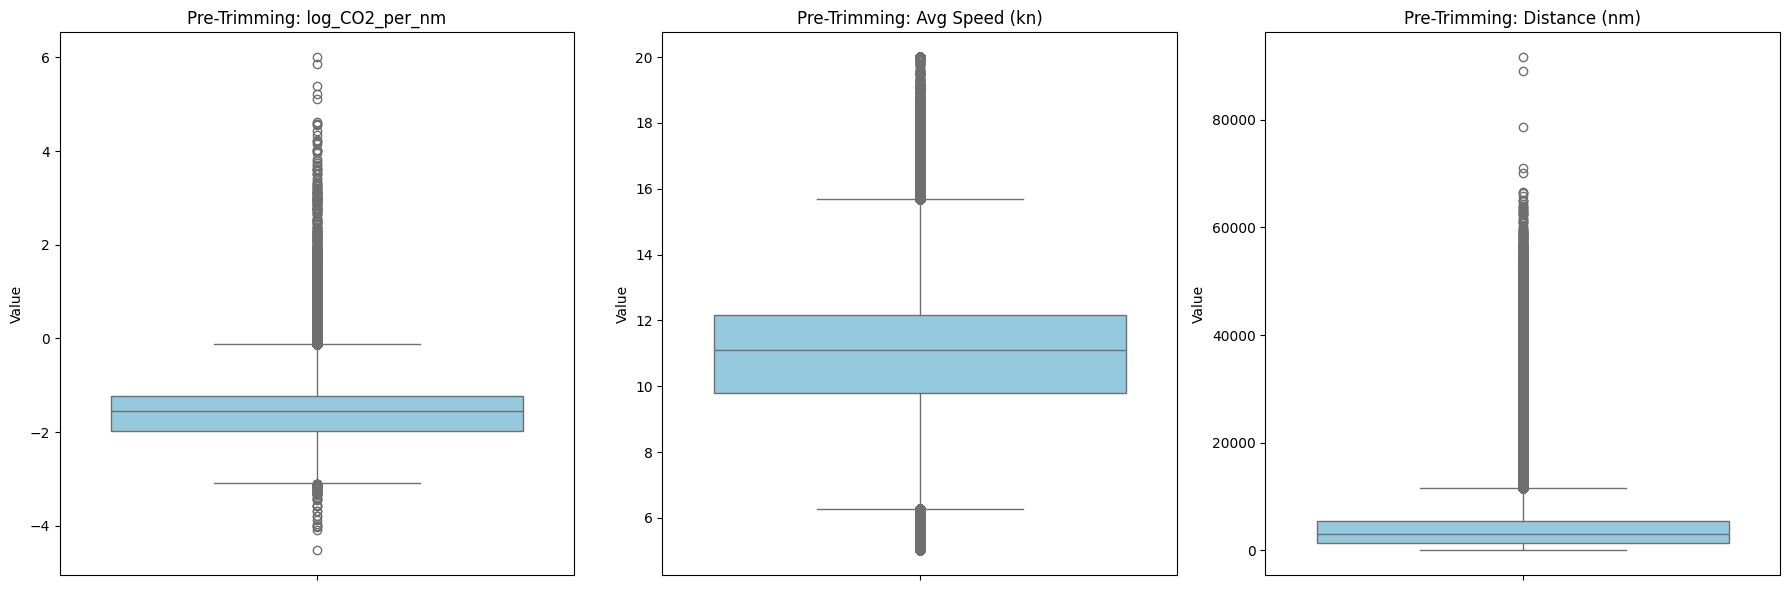

In [8]:
# Outcomes variables
outcomes = [
    "log_CO2_per_nm", "MGO_Share", "HSFO_Share", "VLSFO_Share", 
    "Avg Speed (kn)", "Distance (nm)"
]

# A ship might have 5 voyages in one month. We don't want 5 separate dots; we want the average
# behavior of that ship for that month (required for TWFE regressions).
# This also smooths out daily operational noise (like weather or port delays)
clean_dataset_panel = clean_dataset.groupby(["Vessel Name", "TimeIdx", "Cluster_Name", "YearMonth"])[
    outcomes + ["Interaction", "ETS_Rate", "Post2024", "Vessel Dwt"]].mean().reset_index()

print("Reduced data from", len(clean_dataset), "voyages to", len(clean_dataset_panel), "Vessel/months")

# Maritime data could have weird errors, like a GPS saying a ship did 100 knots or a sensor saying
# it burned 0 fuel. If we keep these, the regression averages will be wrong. 
# We isolate only the unbounded continuous variables for this step (ignoring fuel percentages
# since they are bounded)
vars_to_trim = ["log_CO2_per_nm", "Avg Speed (kn)", "Distance (nm)"]

# Generating diagnostic plots to spot the weird errors

# Create a 1x3 grid of plots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes = axes.flatten()

# Note on how to read the boxplots:
# - the box: the blue rectangle contains the middle 50% of our fleet. This is normal behavior
# - the middle line: the line inside the box is the median average
# - the "whiskers": the lines extending up and down show the acceptable, expected range of variation.
# - the dots: these are the outliers. If a dot is extremely far away (e.g., a dot at
# 80,000 nm for distance), it is surely an error and should be capped or removed before regressions.
for i, col in enumerate(vars_to_trim):
    sns.boxplot(data=clean_dataset_panel, y=col, ax=axes[i], color='skyblue')
    axes[i].set_title(f"Pre-Trimming: {col}", fontsize=12)
    axes[i].set_ylabel("Value")

plt.tight_layout()


# We cap the top 1% and bottom 1% of values to pull extreme errors back to reality
for col in vars_to_trim:
    lower_bound = clean_dataset_panel[col].quantile(0.01)
    upper_bound = clean_dataset_panel[col].quantile(0.99)
    
    clean_dataset_panel[col] = clean_dataset_panel[col].clip(lower_bound, upper_bound)

# This variable allows the model to estimate the "slope" of behavior before the policy hit. 
clean_dataset_panel["ETS_x_Time"] = clean_dataset_panel["ETS_Rate"] * clean_dataset_panel["TimeIdx"]

# Panel integrity and vessel profiling

In [9]:
# In a DiD study, we want to observe the same ships before and after the policy. If a ship only
# appears in 2024 for instance, we don't know its baseline. If it disappears after 2023,
# we don't know its reaction.

pre_vessels  = set(clean_dataset_panel[clean_dataset_panel["Post2024"] == 0]["Vessel Name"])
post_vessels = set(clean_dataset_panel[clean_dataset_panel["Post2024"] == 1]["Vessel Name"])

# Identification of the vessels in both lists
balanced_vessels = pre_vessels & post_vessels

print("Vessels in baseline:", len(pre_vessels))
print("Vessels in treatment:", len(post_vessels))
print("Balanced vessels:", len(balanced_vessels))

# Filter the dataset to keep only these consistent ships
clean_dataset_panel = clean_dataset_panel[clean_dataset_panel["Vessel Name"].isin(balanced_vessels)].copy()

# Ships are often specialized for specific trades (e.g., grain vs. steel)
# We identify the primary commodity for each vessel to use in robustness checks,
# ensuring our results aren't driven by specific commodity market shocks

vessel_commodity = (
    clean_dataset.groupby("Vessel Name")["Commodity"]
    # We take the most frequent commodity (mode) to define the ship's main market
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
    .reset_index()
    .rename(columns={"Commodity": "Primary_Commodity"}))

# Merge this characteristic back into the panel
clean_dataset_panel = clean_dataset_panel.merge(vessel_commodity, on="Vessel Name", how="left")
print(vessel_commodity.head())



# Exportation of the file
export_path = "../Data/prepared_panel_data.csv"
clean_dataset_panel.to_csv(export_path, index=False)
print("Final balanced fleet size:", len(balanced_vessels), "ships")

Vessels in baseline: 19887
Vessels in treatment: 16558
Balanced vessels: 15781
     Vessel Name Primary_Commodity
0      15 TEMMUZ             Grain
1       21 GLORY            Cement
2       21 PANDA            Steels
3       21 SUNNY            Steels
4  30 LET POBEDY             Wheat
Final balanced fleet size: 15781 ships
